# 23CSE301 Machine Learning Capstone — Clustering Track

**Dataset:** Gas Turbine CO and NOx Emission (2011–2015 combined)

**Objective:** Group turbine operating observations using the nine operating-condition features, then interpret CO and NOx emissions by cluster. Emissions and Year are not used as clustering inputs.

**Required algorithms:** K-Means and Agglomerative Hierarchical Clustering.

**Evaluation:** Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Index, elbow curve, linkage comparison, dendrogram, PCA visualisations and t-SNE.

**Reproducibility:** Random seed = 42. K-Means is fitted on all cleaned observations. Hierarchical clustering and its dendrogram use documented samples to control memory and computation.

## 1. Import libraries and set reproducibility

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (8, 5)
warnings.filterwarnings("ignore", category=FutureWarning)

## 2. Load the combined dataset

Place `gas_turbine_combined.csv` or `gas_turbine_combined_full_column_names.csv` in the same folder as this notebook. The code accepts either the abbreviated or descriptive column names.

In [4]:
DATA_CANDIDATES = ["gas_turbine_combined_full_column_names.csv", "gas_turbine_combined.csv"]
DATA_PATH = next((p for p in DATA_CANDIDATES if os.path.exists(p)), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Place gas_turbine_combined_full_column_names.csv or gas_turbine_combined.csv "
        "in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)

# Standardise column names internally so either supplied CSV works.
LONG_TO_SHORT = {
    "Ambient_Temperature": "AT", "Ambient_Pressure": "AP", "Ambient_Humidity": "AH",
    "Air_Filter_Differential_Pressure": "AFDP", "Gas_Turbine_Exhaust_Pressure": "GTEP",
    "Turbine_Inlet_Temperature": "TIT", "Turbine_After_Temperature": "TAT",
    "Turbine_Energy_Yield": "TEY", "Compressor_Discharge_Pressure": "CDP",
    "Carbon_Monoxide_Emission": "CO", "Nitrogen_Oxides_Emission": "NOX",
}
df = df.rename(columns=LONG_TO_SHORT)

print("Loaded file:", DATA_PATH)
print("Raw dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Loaded file: gas_turbine_combined_full_column_names.csv
Raw dataset shape: (36733, 12)
Columns: ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP', 'CO', 'NOX', 'Year']


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,Year
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011


## 3. Dataset audit

Inspect data types, missing values, duplicate rows and summary statistics before preprocessing.

In [5]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("Missing values by column:")
display(df.isna().sum().to_frame("missing_values"))

print("Exact duplicate rows:", df.duplicated().sum())

print("Summary statistics:")
display(df.describe().T.round(3))

Data types:


,dtype
AT,float64
AP,float64
AH,float64
AFDP,float64
GTEP,float64
TIT,float64
TAT,float64
TEY,float64
CDP,float64
CO,float64


Missing values by column:


,missing_values
AT,0
AP,0
AH,0
AFDP,0
GTEP,0
TIT,0
TAT,0
TEY,0
CDP,0
CO,0


Exact duplicate rows: 7
Summary statistics:


,count,mean,std,min,25%,50%,75%,max
AT,36733.0,17.713,7.447,-6.235,11.781,17.801,23.665,37.103
AP,36733.0,1013.070,6.463,985.850,1008.800,1012.600,1017.000,1036.600
AH,36733.0,77.867,14.461,24.085,68.188,80.470,89.376,100.200
AFDP,36733.0,3.926,0.774,2.087,3.356,3.938,4.377,7.611
GTEP,36733.0,25.564,4.196,17.698,23.129,25.104,29.061,40.716
TIT,36733.0,1081.428,17.536,1000.800,1071.800,1085.900,1097.000,1100.900
TAT,36733.0,546.159,6.842,511.040,544.720,549.880,550.040,550.610
TEY,36733.0,133.506,15.619,100.020,124.450,133.730,144.080,179.500
CDP,36733.0,12.061,1.089,9.852,11.435,11.965,12.855,15.159
CO,36733.0,2.372,2.263,0.000,1.182,1.714,2.843,44.103


### Data cleaning

Remove exact duplicate records. Missing/non-finite values in the operating features are handled before clustering. Keep `Year` and emission columns for later interpretation, but do not use them as clustering inputs.

In [6]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Rows before removing exact duplicates:", rows_before)
print("Rows after removing exact duplicates:", len(df))
print("Exact duplicates removed:", rows_before - len(df))

# Replace infinite values with NaN, then remove rows missing required numeric inputs.
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)
required_for_analysis = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP", "CO", "NOX"]
missing_required = [c for c in required_for_analysis if c not in df.columns]
if missing_required:
    raise ValueError(f"Required columns are missing: {missing_required}")
rows_before_missing = len(df)
df = df.dropna(subset=required_for_analysis).reset_index(drop=True)
print("Rows removed due to missing/non-finite required values:", rows_before_missing - len(df))
print("Cleaned dataset shape:", df.shape)
print("Missing values remaining in required columns:", int(df[required_for_analysis].isna().sum().sum()))

Rows before removing exact duplicates: 36733
Rows after removing exact duplicates: 36726
Exact duplicates removed: 7
Rows removed due to missing/non-finite required values: 0
Cleaned dataset shape: (36726, 12)
Missing values remaining in required columns: 0


## 4. Select features for clustering

Use all nine turbine operating-condition features. Keep CO and NOx out of model fitting so they can be compared across the resulting clusters afterward.

In [7]:
operating_features = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]
emission_features = ["CO", "NOX"]

missing_columns = [c for c in operating_features + emission_features if c not in df.columns]
if missing_columns:
    raise ValueError(f"Expected columns not found: {missing_columns}")

X = df[operating_features].astype(float).copy()
print("Number of clustering features:", X.shape[1])
print("Features used:", operating_features)
print("Rows used for K-Means:", len(X))
display(X.head())

Number of clustering features: 9
Features used: ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']
Rows used for K-Means: 36726


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910


### Quick exploratory visualisations
These plots help inspect distributions and relationships before clustering.

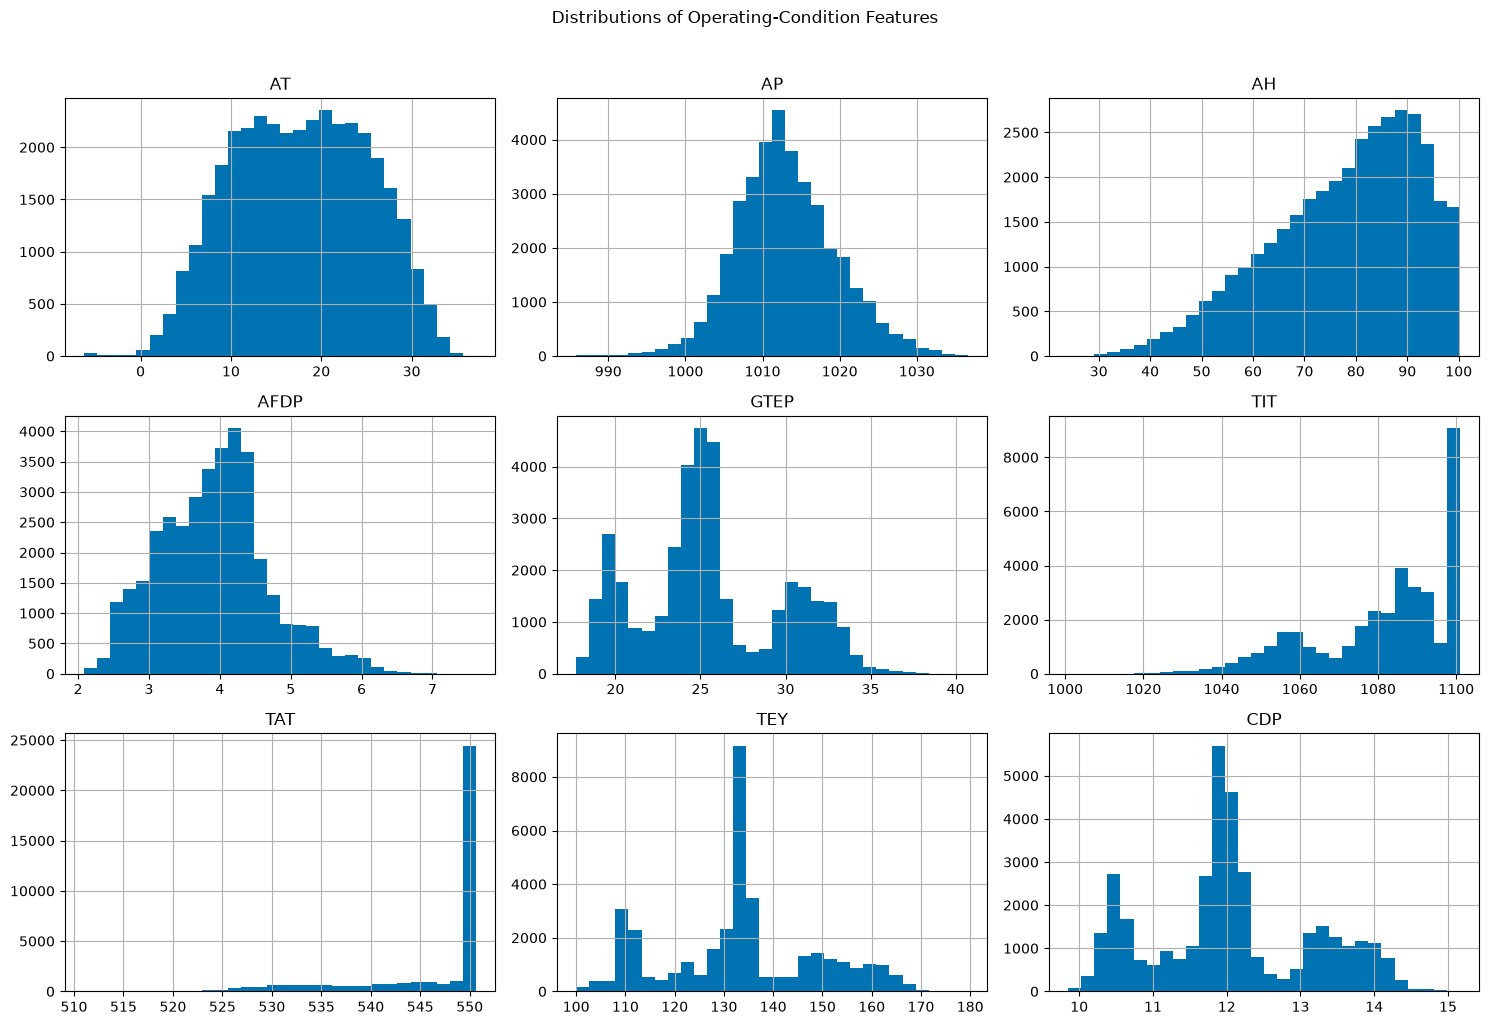

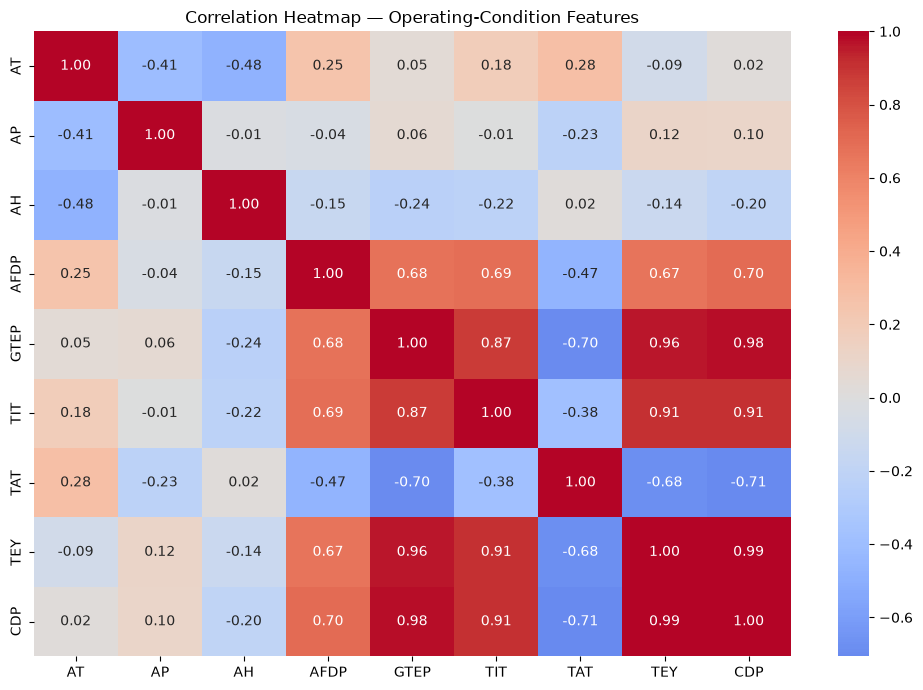

In [8]:
X.hist(figsize=(15, 10), bins=30)
plt.suptitle("Distributions of Operating-Condition Features", y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap — Operating-Condition Features")
plt.tight_layout()
plt.show()

## 5. Scale the numerical features

K-Means and hierarchical clustering are distance-based, so feature scaling is necessary. Use `StandardScaler` as the main baseline. The notebook retains only one full scaled matrix to reduce memory usage.

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled matrix shape:", X_scaled.shape)
print("Data type:", X_scaled.dtype)
print("Approximate feature means:", np.round(X_scaled.mean(axis=0), 3))
print("Approximate feature standard deviations:", np.round(X_scaled.std(axis=0), 3))

Scaled matrix shape: (36726, 9)
Data type: float64
Approximate feature means: [ 0.  0. -0.  0. -0.  0. -0.  0. -0.]
Approximate feature standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 6. K-Means — Elbow curve

Fit K-Means for a range of `k` values on the full cleaned dataset. Inertia decreases as `k` increases; use the elbow as one piece of evidence rather than an automatic decision rule.

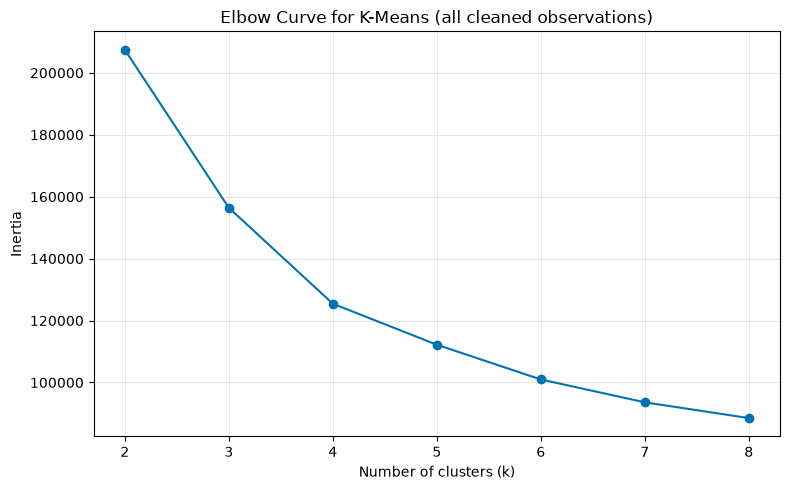

In [10]:
k_values = range(2, 9)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Curve for K-Means (all cleaned observations)")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### K-Means — compare candidate values of k

For each candidate, fit K-Means on all cleaned rows. Compute Silhouette on the same fixed evaluation subset to keep the calculation manageable; compute Davies–Bouldin and Calinski–Harabasz on all rows. The sample size is shown explicitly. Consider all metrics, the elbow curve, cluster sizes and interpretability when choosing `k`.

,k,Inertia (all rows),Silhouette (sample n=5000),Davies-Bouldin (all rows),Calinski-Harabasz (all rows),Smallest cluster (all rows),Largest cluster (all rows)
0,2,207448.7025,0.3723,1.0867,21789.4129,9622,27104
1,3,156429.1718,0.3066,1.2180,20436.2625,8696,19007
2,4,125444.4254,0.2953,1.1797,20012.3651,5949,13118
3,5,112200.6209,0.2622,1.2460,17864.0553,5782,9049
4,6,100979.9688,0.2561,1.2419,16694.8706,4570,7561
5,7,93598.8610,0.2466,1.3501,15491.7197,2786,7270
6,8,88507.3133,0.2326,1.4005,14343.8563,2763,7166


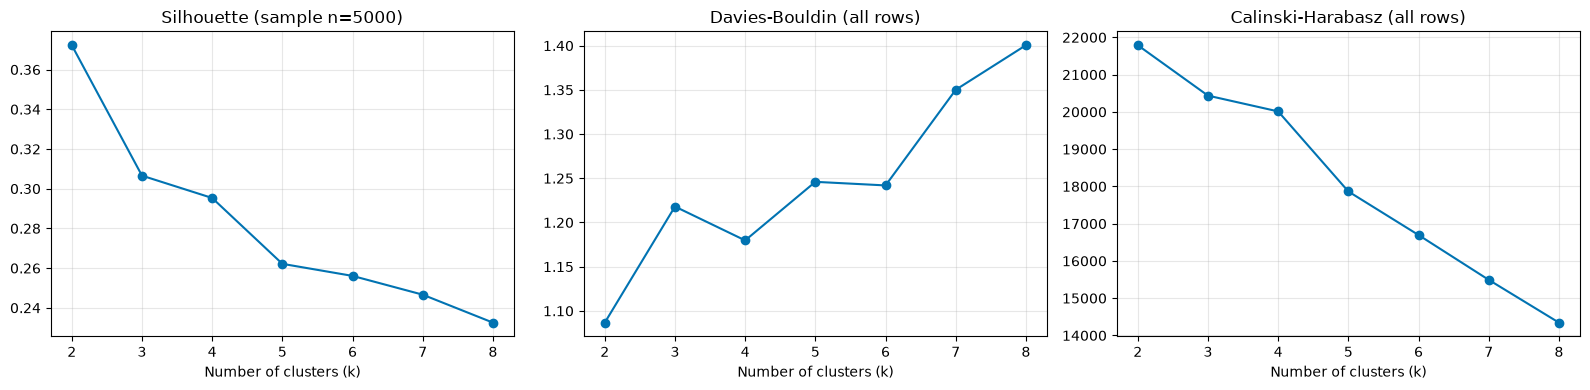

In [11]:
# Fixed subset used only to estimate Silhouette for candidate K values.
SILHOUETTE_SAMPLE_SIZE = min(5000, len(X_scaled))
eval_rng = np.random.RandomState(RANDOM_STATE)
eval_positions = np.sort(eval_rng.choice(len(X_scaled), size=SILHOUETTE_SAMPLE_SIZE, replace=False))

k_rows = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)  # fit on all cleaned rows
    subset_labels = labels[eval_positions]
    subset_X = X_scaled[eval_positions]
    sizes = np.bincount(labels, minlength=k)
    k_rows.append({
        "k": k,
        "Inertia (all rows)": model.inertia_,
        f"Silhouette (sample n={SILHOUETTE_SAMPLE_SIZE})": silhouette_score(subset_X, subset_labels),
        "Davies-Bouldin (all rows)": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz (all rows)": calinski_harabasz_score(X_scaled, labels),
        "Smallest cluster (all rows)": int(sizes.min()),
        "Largest cluster (all rows)": int(sizes.max()),
    })
k_table = pd.DataFrame(k_rows)
display(k_table.round(4))

sil_col = f"Silhouette (sample n={SILHOUETTE_SAMPLE_SIZE})"
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, [sil_col, "Davies-Bouldin (all rows)", "Calinski-Harabasz (all rows)"]):
    ax.plot(k_table["k"], k_table[col], marker="o")
    ax.set_title(col)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(list(k_values))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Fit the selected K-Means model

Set `KMEANS_K` after reviewing the elbow curve and comparison table. The default is `3` as a transparent starting candidate, not a claim that it is universally optimal. The final K-Means model is fitted on every cleaned observation.

In [12]:
# Review the elbow curve, metric table, cluster sizes and interpretability before finalising k.
# Default candidate is 3; change this value only when your evidence supports another choice.
KMEANS_K = 3
print("K-Means cluster count selected for analysis:", KMEANS_K)

kmeans = KMeans(n_clusters=KMEANS_K, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)  # all cleaned observations

df["KMeans_Cluster"] = kmeans_labels
print("K-Means cluster counts on the full cleaned dataset:")
display(df["KMeans_Cluster"].value_counts().sort_index().to_frame("instances"))

K-Means cluster count selected for analysis: 3
K-Means cluster counts on the full cleaned dataset:


,instances
KMeans_Cluster,
0,19007
1,9023
2,8696
